# Dong et al. 2020 — Prostate Cancer — Step 03: Signatures (Gate 2)

**Gate 2.** Does the embryonic module pattern appear? For a **non-branching** manifold (this dataset), the
pass condition is a **shared Gast/pSom gradient with Crest as an inverse/terminal readout** — programs
present but not resolved into two competing arms (`01_task.md` §1–2). This still **passes (GO)**; with no
bifurcation, **Gate 3 is NA**.

The deliverable signature UMAPs show **raw per-cell scores** (`04_test.md` Chen/Sun: graph-smoothing may aid
the geography read in the notebook, but the deliverable shows raw). Panels use the house `(3.5,1.5)` linear
aspect on the shared `X_umap_lin` orientation, with external colorbars in `colorbars/`.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad'))
print('loaded manifold:', adata.shape[0], 'cells | scores present:', [m for m in ['Gast','pSom','Crest'] if m in adata.obs])

loaded manifold: 9698 cells | scores present: ['Gast', 'pSom', 'Crest']


In [3]:
# re-score canonically (score_genes with the union control pool) for the deliverable
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('global module means (raw):', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})

Gast: 71/81 genes present
pSom: 83/98 genes present
Crest: 99/104 genes present
global module means (raw): {'Gast': 0.035, 'pSom': 0.1, 'Crest': -0.041}


In [4]:
# Gate 2 evidence: module geography (smoothed) + gradient along pseudotime
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('\ngradient along pseudotime (Spearman rho on smoothed):')
for sn in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  {sn}: rho = {spearmanr(t, adata.obs[sn])[0]:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'\nNeural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('\nGATE 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching)')
print('GATE 3: no Gast/pSom cross-repression arms -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.90
  Crest_sm vs Gast_sm: r = -0.39
  Crest_sm vs pSom_sm: r = -0.53

gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.581
  pSom_sm: rho = -0.714
  Crest_sm: rho = +0.794

Neural-crest-high decile mean pseudotime = 0.98 (terminal if ~1)

GATE 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching)
GATE 3: no Gast/pSom cross-repression arms -> NA


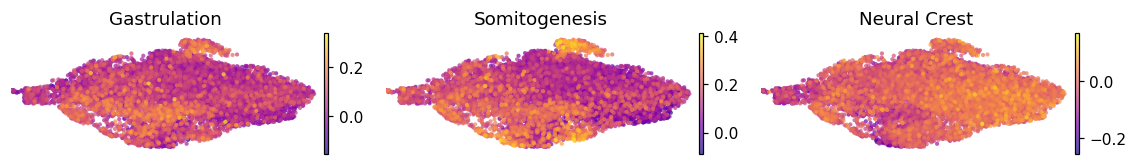

In [5]:
# combined signature panel (raw scores) on the house linear layout — quick look
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
titles = {'Gast':'Gastrulation','pSom':'Somitogenesis','Crest':'Neural Crest'}
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax, (m, tt) in zip(axes, titles.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=tt)
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
fig.tight_layout(); plt.show()

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


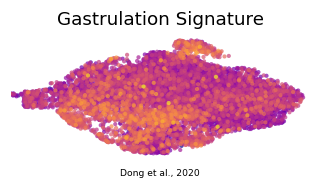

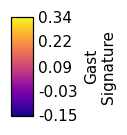

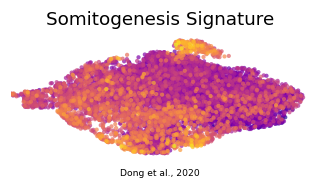

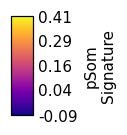

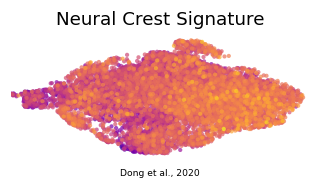

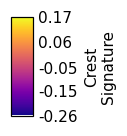

In [6]:
# deliverable signature UMAPs (raw scores) + external colorbars — house (3.5,1.5), reference style
titles_full = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles_full[m])
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.12, 'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show()
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [7]:
adata.write(os.path.join(pth_in, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (9698, 15672)


## Gate 2 verdict — **GO** (non-branching); Gate 3 — **NA**

The three embryonic modules form the reference **non-branching** pattern: **Gast and pSom co-vary** (smoothed
r ≈ +0.9, a shared gradient — no two diverging arms) and **both oppose Crest**, which peaks at the
neural-crest terminus (Crest-high decile at mean pseudotime ≈ 1). Programs are present and developmentally
ordered but collapsed onto a single axis. This **passes Gate 2 (GO)**; with no bifurcation there is no
cross-repression to test, so **Gate 3 is NA**. Crest peaks at the terminus rather than a Gast-leaning arm, so
no Crest-arm inversion flag applies. We proceed to the unconditional **04_expression** (EMT-TF) step.